In [1]:
%cd "../data/community_editing"

/global/scratch/users/jackdemaray/is110-insertion-mapping/data/community_editing


/tmp/ipykernel_2811716/784960075.py:42: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


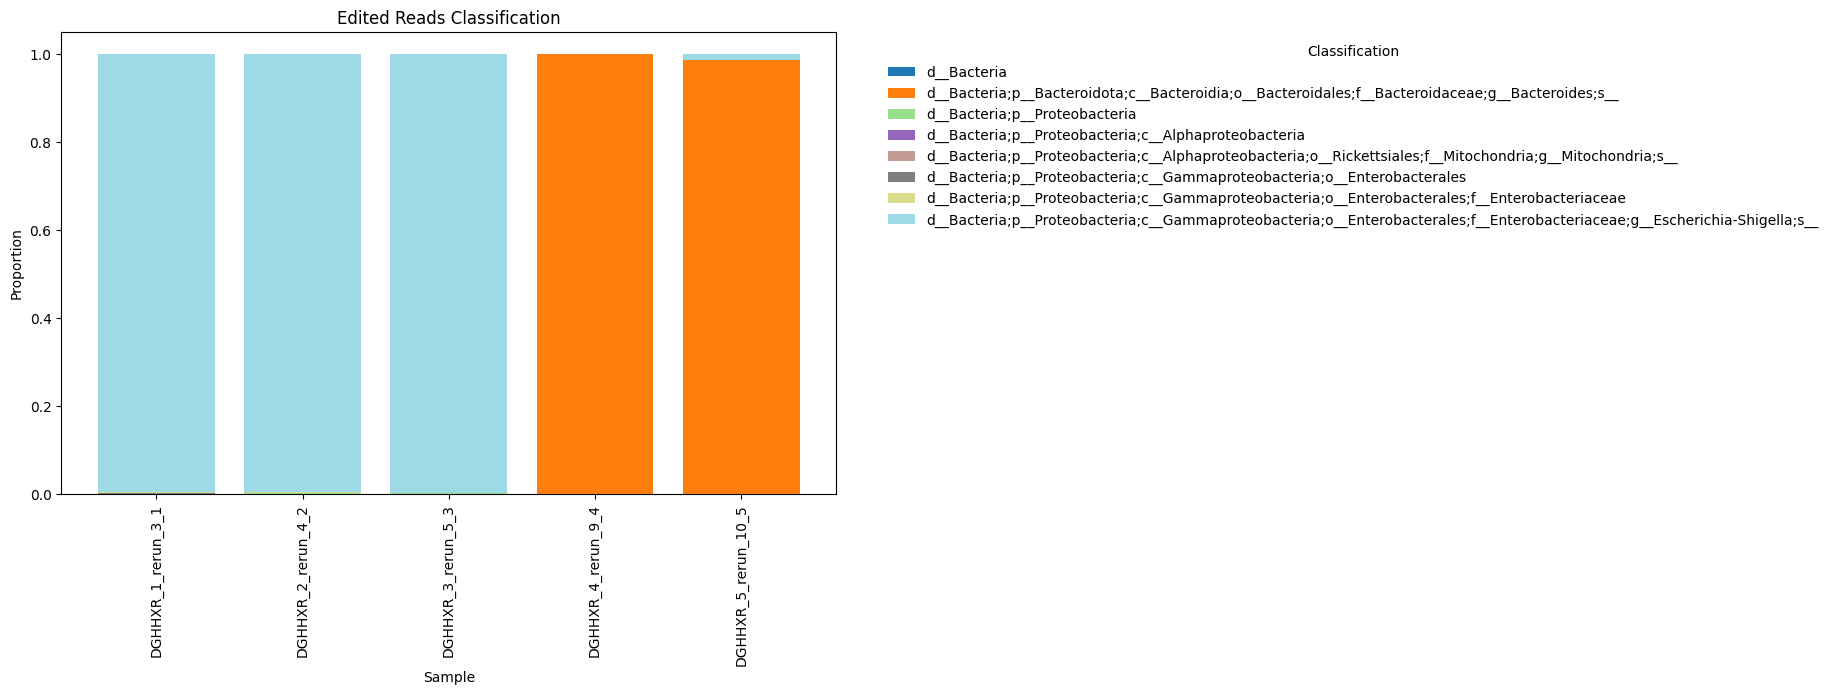

/tmp/ipykernel_2811716/784960075.py:42: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


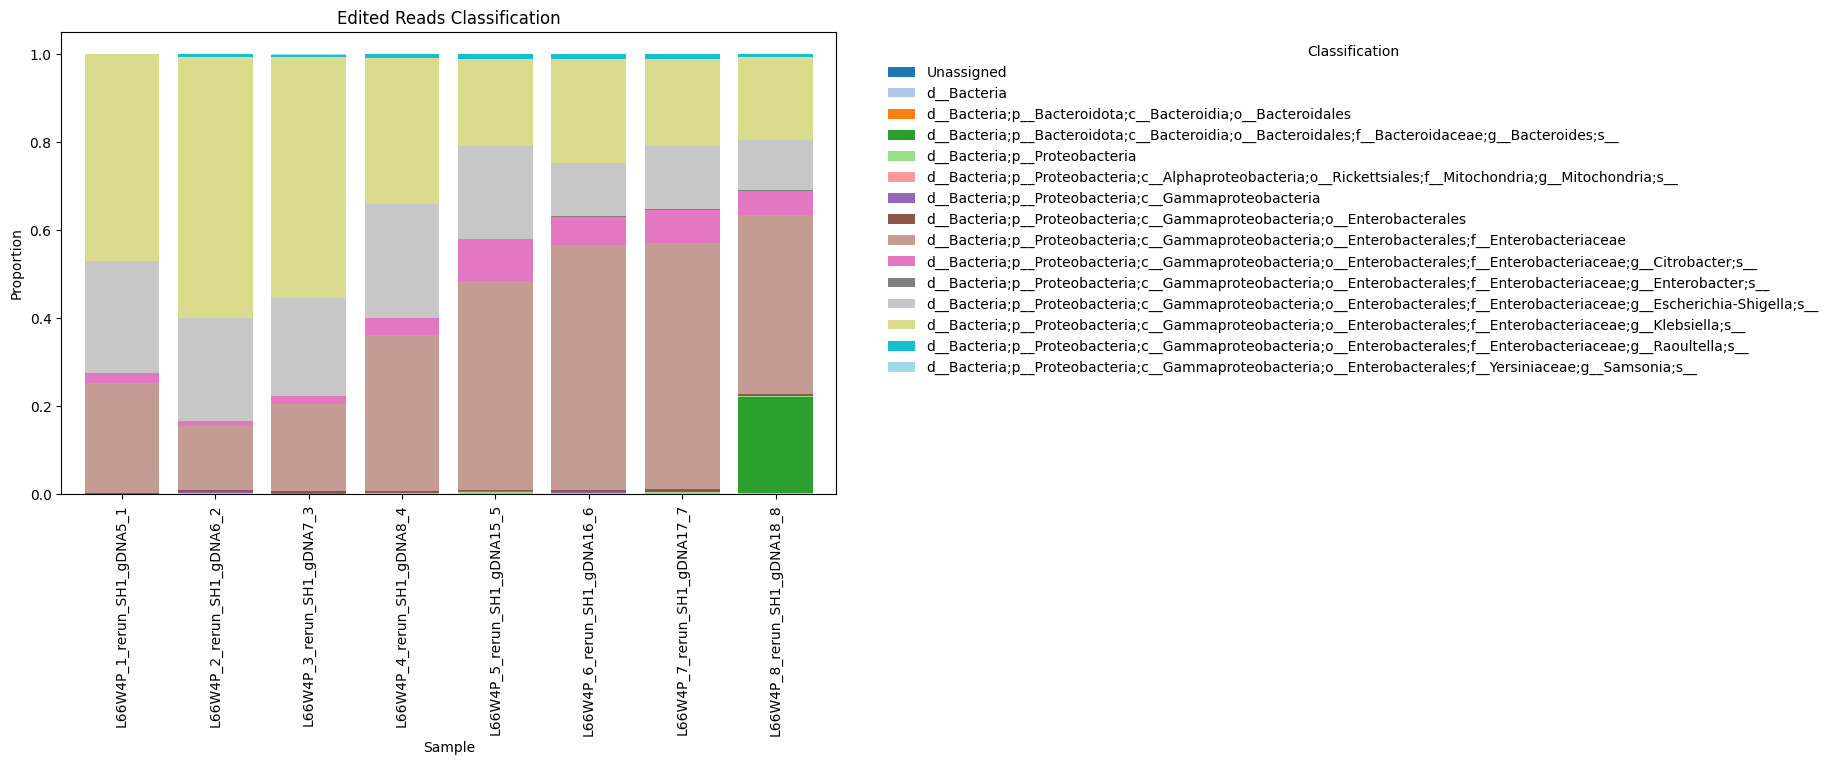

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import glob
import os
import sys

samples = glob.glob("*")

def plot_samples(samples):
    dfs = []

    for sample in samples:
        df_i = pd.read_csv(f"{sample}/taxonomy/taxonomy_table.tsv", sep="\t")
        df_i["Sample"] = sample
        dfs.append(df_i)

    df = pd.concat(dfs)

    df_pivot = df.pivot_table(
        index='Sample',
        columns='classification',
        values='proportion',
        aggfunc='sum',  # in case of duplicates
        fill_value=0
    )

    # Plot
    df_pivot.plot(
        kind='bar',
        stacked=True,
        colormap='tab20',  # You can choose other color maps
        figsize=(10, 6),
        width=.8

    )

    plt.ylabel('Proportion')
    plt.title('Edited Reads Classification')
    plt.legend(title='Classification', bbox_to_anchor=(1.05, 1), loc='upper left', 
            frameon=False)
    plt.tight_layout()
    plt.show()


DGHHXR = glob.glob("DGHHXR_*")
plot_samples(DGHHXR)
L66W4P = glob.glob("L66W4P_*")
plot_samples(L66W4P)

In [7]:
samples = DGHHXR + L66W4P
dfs = []

for sample in samples:
    df_i = pd.read_csv(f"{sample}/taxonomy/taxonomy_table.tsv", sep="\t")
    df_i["Sample"] = sample
    dfs.append(df_i)

df = pd.concat(dfs)

df_pivot = df.pivot_table(
    index='Sample',
    columns='classification',
    values='proportion',
    aggfunc='sum',  # in case of duplicates
    fill_value=0
)
df.to_csv("DGHHXR_L66W4P.csv", index=False)